<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/%E8%87%AA%E7%94%B1%E8%90%BD%E9%AB%94%E5%AF%A6%E9%A9%97%E8%88%87%E9%87%8D%E5%8A%9B%E5%8A%A0%E9%80%9F%E5%BA%A6%E6%93%AC%E5%90%88%E5%88%86%E6%9E%90.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 自由落體實驗與重力加速度擬合分析

本實驗旨在探討自由落體運動中，高度（控制變因 $h$）與下落時間（應變變因 $t$）之間的物理關係，並透過統計學與曲線擬合方法精確推導出當地的重力加速度 $g$。

---

## 1. 物理原理與理論模型
根據古典力學，一個物體自靜止釋放進行自由落體運動，在忽略空氣阻力的情況下，其下落高度 $h$ 與時間 $t$ 的關係遵循以下運動學公式：
$$h = \frac{1}{2}gt^2$$
其中：
* $h$：下落高度（單位：公尺, $\text{m}$），作為實驗中的**控制變因**。
* $t$：下落時間（單位：秒, $\text{s}$），作為實驗中的**應變變因**。
* $g$：重力加速度（單位：$\text{m/s}^2$），為本實驗欲求解的常數。

### 線性模型轉換
若直接對 $t$ 與 $h$ 進行擬合，此模型為非線性。為了簡化計算並提高分析的直觀性，我們可以將公式兩邊平方，重新整理為以高度 $h$ 為自變數、時間平方 $t^2$ 為應變數的線性關係式：
$$t^2 = \left(\frac{2}{g}\right) h$$
此時，若令 $y = t^2$ 且 $x = h$，則兩者呈現穿過原點的直線關係：
$$y = \beta x$$
其中直線的斜率為 $\beta = \frac{2}{g}$。一旦擬合出斜率 $\beta$，即可反推重力加速度：
$$g = \frac{2}{\beta}$$

---

## 2. 數據分析方法與統計學概念
為了消除量測時產生的隨機誤差，我們對每個高度進行了 **10 次重複實驗**，並採用以下優化後的統計與擬合步驟進行分析：

### A. 優先進行時間 $t$ 的統計 (Mean and Standard Deviation of $t$)
在進行任何乘方轉換前，我們先針對每個高度 $h_j$ 的 10 次原始時間數據 $t_i$ 計算其平均值與標準差，以獲得最直接的量測統計特徵：
1. **時間平均值 (Mean of $t$)**：
   $$\overline{t} = \frac{1}{N}\sum_{i=1}^{N} t_i$$
2. **時間標準差 (Standard Deviation of $t$, $\sigma_{t}$)**：
   $$\sigma_{t} = \sqrt{\frac{1}{N-1}\sum_{i=1}^{N}(t_i - \overline{t})^2}$$

### B. 後續分析應用與時間平方統計
在獲得原始時間的統計量後，為了配合線性理論模型 $t^2 = \beta h$，我們接著計算每一次實驗的時間平方 $t^2$。對於各個高度下時間平方的平均值 $\overline{t^2}$ 與標準差 $\sigma_{t^2}$，我們將其作為後續加權線性擬合的輸入數據。

### C. 含誤差的加權線性擬合 (Weighted Linear Fit)
在進行斜率 $\beta$ 的擬合時，由於不同高度下的量測誤差不盡相同，我們採用**加權最小平方法 (Weighted Least Squares)**。

此方法將各組高度下 $t^2$ 的標準差 $\sigma_{t^2}$ 倒數之平方作為權重 $w_j = 1/\sigma_{t^2, j}^2$。擬合的目標是使加權殘差平方和達到最小：
$$\text{Weighted RSS}(\beta) = \sum_{j=1}^{M} w_j \left[ \overline{t^2}_j - \beta h_j \right]^2$$
透過此方法估計出的斜率 $\beta$ 及其標準不確定度 $\sigma_\beta$，更能如實反映各觀測點的精度貢獻。

### D. 誤差傳遞 (Error Propagation)
當由斜率 $\beta$ 換算為重力加速度 $g = \frac{2}{\beta}$ 時，斜率的不確定度 $\sigma_\beta$ 也會傳遞至 $g$。根據微積分誤差傳遞公式：
$$\sigma_g = \left| \frac{dg}{d\beta} \right| \sigma_\beta = \frac{2}{\beta^2} \sigma_\beta$$
最終我們便可得出重力加速度的實驗估計值及其不確定度：$g \pm \sigma_g$。

In [ ]:
import pandas as pd
import numpy as np

# 設定隨機種子以確保每次執行結果相同 (模擬實驗誤差)
np.random.seed(42)

# 定義三個實驗高度 (控制變因)
heights = [1.0, 1.5, 2.0]
num_trials = 10  # 每個高度進行十次實驗

# 理論重力加速度 (用來產生模擬時間數據)
g_true = 9.81

experiment_records = []

# 模擬實驗量測時間 (t = sqrt(2h/g) + 隨機誤差)
for h in heights:
    t_theoretical = np.sqrt(2 * h / g_true)
    for trial in range(1, num_trials + 1):
        # 加上微小的量測誤差 (標準差為 0.015 秒的常態分佈)
        t_measured = t_theoretical + np.random.normal(0, 0.015)
        # 確保時間不為負數
        t_measured = max(0.01, t_measured)

        experiment_records.append({
            "height": h,
            "trial": trial,
            "time": round(t_measured, 3)
        })

# 建立 DataFrame
df = pd.DataFrame(experiment_records)

# 根據公式計算每次實驗的重力加速度 g = 2 * h / t^2
df['calculated_g'] = 2 * df['height'] / (df['time'] ** 2)

# 顯示前 15 筆實驗數據供參考
print("--- 實驗數據前 15 筆記錄 ---")
display(df.head(15))

# 統計每個高度的平均時間、時間標準差、平均 g 值與 g 的標準差
summary_by_height = df.groupby('height').agg(
    mean_time=('time', 'mean'),
    std_time=('time', 'std'),
    mean_g=('calculated_g', 'mean'),
    std_g=('calculated_g', 'std')
).reset_index()

print("\n--- 各高度（控制變因）10次實驗的時間與重力加速度統計結果 ---")
display(summary_by_height)

# 計算整體的平均重力加速度
overall_average_g = df['calculated_g'].mean()
print(f"\n所有實驗（共 {len(df)} 次）的總平均重力加速度 (g) = {overall_average_g:.3f} m/s²")

--- 實驗數據前 15 筆記錄 ---


,height,trial,time,calculated_g
0,1.0,1,0.459,9.493025
1,1.0,2,0.449,9.920586
2,1.0,3,0.461,9.410835
3,1.0,4,0.474,8.901707
4,1.0,5,0.448,9.964923
5,1.0,6,0.448,9.964923
6,1.0,7,0.475,8.864266
7,1.0,8,0.463,9.329707
8,1.0,9,0.444,10.145280
9,1.0,10,0.460,9.451796



--- 各高度（控制變因）10次實驗的時間與重力加速度統計結果 ---


,height,mean_time,std_time,mean_g,std_g
0,1.0,0.4581,0.010857,9.544705,0.448087
1,1.5,0.5412,0.011497,10.254985,0.435866
2,2.0,0.6352,0.012372,9.923809,0.381379



所有實驗（共 30 次）的總平均重力加速度 (g) = 9.908 m/s²


--- 各高度時間 (t) 的平均值與標準差 ---


,height,mean_time,std_time
0,1.0,0.4581,0.010857
1,1.5,0.5412,0.011497
2,2.0,0.6352,0.012372



--- 含誤差之線性擬合結果 ---
擬合斜率 (2/g)             = 0.2015 ± 0.0050 s²/m
推導重力加速度平均值 (g)   = 9.9250 m/s²
推導重力加速度標準差 (std) = 0.2445 m/s²


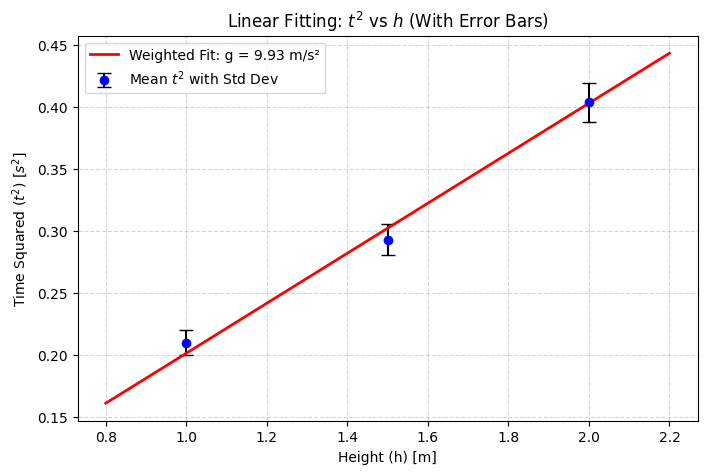

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# 1. 在原始 DataFrame 中計算每一次實驗的時間平方 (t^2)
df['time_sq'] = df['time'] ** 2

# 2. 統計每個高度下，時間 (t) 的平均值與標準差
summary_t = df.groupby('height').agg(
    mean_time=('time', 'mean'),
    std_time=('time', 'std')
).reset_index()

print("--- 各高度時間 (t) 的平均值與標準差 ---")
display(summary_t)

# 3. 定義線性擬合模型：t^2 = slope * h, 其中 slope = 2 / g
def linear_model(h, slope):
    return slope * h

# 為了進行擬合，我們仍需要各高度 t^2 的平均值與標準差
summary_tsq = df.groupby('height').agg(
    mean_t2=('time_sq', 'mean'),
    std_t2=('time_sq', 'std')
).reset_index()

# 準備擬合數據
x_data_linear = summary_tsq['height'].values
y_data_linear = summary_tsq['mean_t2'].values
y_errors = summary_tsq['std_t2'].values

# 4. 進行含誤差（加權）的線性擬合
popt_linear, pcov_linear = curve_fit(
    linear_model,
    x_data_linear,
    y_data_linear,
    sigma=y_errors,
    absolute_sigma=True
)

slope_fit = popt_linear[0]
slope_std = np.sqrt(pcov_linear[0][0])

# 5. 從斜率推導重力加速度 g (g = 2 / slope)
g_fit_linear = 2 / slope_fit
g_std_linear = (2 / (slope_fit ** 2)) * slope_std

print("\n--- 含誤差之線性擬合結果 ---")
print(f"擬合斜率 (2/g)             = {slope_fit:.4f} ± {slope_std:.4f} s²/m")
print(f"推導重力加速度平均值 (g)   = {g_fit_linear:.4f} m/s²")
print(f"推導重力加速度標準差 (std) = {g_std_linear:.4f} m/s²")

# 6. 繪製線性擬合與誤差條圖 (Errorbar)
plt.figure(figsize=(8, 5))
plt.errorbar(
    summary_tsq['height'],
    summary_tsq['mean_t2'],
    yerr=summary_tsq['std_t2'],
    fmt='o',
    color='blue',
    ecolor='black',
    capsize=5,
    label='Mean $t^2$ with Std Dev'
)

# 繪製擬合直線
h_line = np.linspace(0.8, 2.2, 100)
t2_line = linear_model(h_line, slope_fit)
plt.plot(h_line, t2_line, color='red', linewidth=2, label=f'Weighted Fit: g = {g_fit_linear:.2f} m/s²')

plt.title('Linear Fitting: $t^2$ vs $h$ (With Error Bars)')
plt.xlabel('Height (h) [m]')
plt.ylabel('Time Squared ($t^2$) [$s^2$]')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()